# 第 36 课｜滚动窗口、指数加权与回撤

本 Notebook 对应「365 天量化金融」第 36 课。课程代码主线来自本地视频、课件截图和 Whisper 口播整理；在此基础上补充量化数据语义、断言、性能验证和方法边界。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/36_youtube-Tn_M5INHO0Q/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子生成的离线模拟行情（**非真实股票数据**）
- 状态：可运行学习稿；不代表策略收益承诺

> **数据声明**：本 Notebook 的证券名称、价格和成交量均为教学模拟数据。它用于稳定复现计算方法，不能用于评价真实证券、市场规律或策略收益。

## 本节量化问题

本课输入一只虚构股票的日频**复权收盘价**，依次回答四个问题：

1. 最近若干个观测的均值和离散程度如何变化；
2. 固定观测窗口、累计窗口和指数衰减权重有何区别；
3. 如何从简单收益率构造净值、历史峰值和回撤；
4. 为什么指标只使用历史数据，仍不代表交易收益没有未来信息。

输出包括带日期标签的 SMA、布林带、EMA、净值和回撤，以及一期延迟与错误同 bar 计算的对照。每个较难 API 先用确定性小序列得到可手工核对的结果，再应用到模拟行情。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 先看原始长表

原始 CSV 是长表：同一交易日有多只虚构股票，每行是一只股票的一天记录。先按日期和股票排序展示，确认字段和数据形态，再筛选单一标的。

In [2]:
# 读取并展示原始长表；按日期排序后可直接看到同一天的多只股票。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
print("原始表形状：", daily.shape)
print("原始列：", daily.columns.tolist())
display_columns = ["date", "symbol", "sector", "adj_close", "volume"]
daily.sort_values(["date", "symbol"]).loc[:, display_columns].head(12)

原始表形状： (4536, 9)
原始列： ['date', 'symbol', 'sector', 'open', 'high', 'low', 'close', 'adj_close', 'volume']


,date,symbol,sector,adj_close,volume
0,2023-01-03,BANK_A,金融,11.7218,2822797
3024,2023-01-03,ENERGY_A,能源,6.0296,5425851
1512,2023-01-03,EV_A,新能源,27.5575,5113762
756,2023-01-03,INSURE_A,金融,41.7118,2075343
2268,2023-01-03,POWER_A,公用事业,8.0817,3733504
3780,2023-01-03,TECH_A,科技,36.2134,6241108
1,2023-01-04,BANK_A,金融,11.6934,1999548
3025,2023-01-04,ENERGY_A,能源,6.0138,2697822
1513,2023-01-04,EV_A,新能源,27.5189,4037866
757,2023-01-04,INSURE_A,金融,41.9968,5993759


## 筛选 `TECH_A` 的复权收盘价

`daily["symbol"].eq("TECH_A")` 产生逐行布尔条件；`.loc[行条件, 列标签]` 同时选择行和列。随后把 `date` 设为索引并按日期排序，得到一维 `Series`。

这里保留名称 `adj_close`，避免把复权收盘价误写成未复权的普通 `close`。

In [3]:
# 从长表筛选 TECH_A，并构造成“日期 → 复权收盘价”的带标签序列。
tech_rows = daily.loc[
    daily["symbol"].eq("TECH_A"),
    ["date", "symbol", "adj_close"],
].copy()

adj_close = (
    tech_rows
    .set_index("date")["adj_close"]
    .sort_index()
    .rename("adj_close")
)
assert adj_close.index.is_monotonic_increasing
assert adj_close.index.is_unique
assert adj_close.gt(0).all()
print("TECH_A 记录数：", len(adj_close))
print("日期范围：", adj_close.index.min().date(), "→", adj_close.index.max().date())
adj_close.head().to_frame()

TECH_A 记录数： 756
日期范围： 2023-01-03 → 2025-11-25


,adj_close
date,
2023-01-03,36.2134
2023-01-04,36.5943
2023-01-05,36.0263
2023-01-06,35.9828
2023-01-09,35.7220


## 从价格计算简单收益率

`pct_change(fill_method=None)` 按时间索引向下计算

```text
当日简单收益率 = 当日复权收盘价 / 前一日复权收盘价 - 1
```

第一日没有前一日价格，因此收益率为 `NaN`。`fill_method=None` 明确禁止 Pandas 先用旧价格填补缺失值；真实行情中的其他缺失收益不能随意当作 0。

In [4]:
# 计算相邻交易日的简单收益率，并保留日期标签。
returns = adj_close.pct_change(fill_method=None).rename("simple_return")
assert pd.isna(returns.iloc[0])
assert returns.iloc[1:].notna().all()

pd.concat(
    [adj_close, returns],
    axis=1,
).head()

,adj_close,simple_return
date,,
2023-01-03,36.2134,NaN
2023-01-04,36.5943,0.010518
2023-01-05,36.0263,-0.015522
2023-01-06,35.9828,-0.001207
2023-01-09,35.7220,-0.007248


## 课程示例 1：先用小序列理解 `rolling` 与 `min_periods`

`rolling(window=3)` 在每个位置取“包含当前位置在内的最近 3 个观测”，不是 3 个自然日。

- `min_periods=3`：必须凑满 3 个有效观测才输出；
- `min_periods=2`：有 2 个有效观测即可提前输出；
- `.mean()`：沿时间方向对每个窗口求均值。

In [5]:
# 用 5 个确定值核对滚动窗口，不依赖模拟行情。
rolling_demo = pd.Series(
    [10.0, 11.0, 13.0, 12.0, 14.0],
    index=["D1", "D2", "D3", "D4", "D5"],
    name="price",
)
rolling_demo_table = pd.DataFrame({
    "price": rolling_demo,
    "ma3_full": rolling_demo.rolling(window=3, min_periods=3).mean(),
    "ma3_min2": rolling_demo.rolling(window=3, min_periods=2).mean(),
})

assert np.isclose(rolling_demo_table.loc["D3", "ma3_full"], (10 + 11 + 13) / 3)
assert np.isclose(rolling_demo_table.loc["D5", "ma3_full"], (13 + 12 + 14) / 3)
rolling_demo_table.round(4)

,price,ma3_full,ma3_min2
D1,10.0,NaN,NaN
D2,11.0,NaN,10.5000
D3,13.0,11.3333,11.3333
D4,12.0,12.0000,12.0000
D5,14.0,13.0000,13.0000


### 回到真实序列：20 个观测的简单移动平均

`window=20` 表示最近 20 条价格记录；对本课的完整工作日样例，通常近似 20 个交易日，但它不是 20 个自然日。`min_periods=20` 要求完整窗口，`min_periods=5` 则用于观察提前输出的差异。

In [6]:
# 对复权收盘价分别计算完整窗口和允许提前输出的 SMA20。
ma20 = adj_close.rolling(window=20, min_periods=20).mean().rename("sma20")
ma20_early = adj_close.rolling(window=20, min_periods=5).mean().rename("sma20_min5")

assert ma20.iloc[:19].isna().all()
assert ma20_early.iloc[:4].isna().all()
assert np.isclose(ma20.iloc[19], adj_close.iloc[:20].mean())
print("SMA20 首个有效日期：", ma20.first_valid_index().date())
pd.concat(
    [adj_close, ma20, ma20_early],
    axis=1,
).head(22).round(4)

SMA20 首个有效日期： 2023-01-30


,adj_close,sma20,sma20_min5
date,,,
2023-01-03,36.2134,NaN,NaN
2023-01-04,36.5943,NaN,NaN
2023-01-05,36.0263,NaN,NaN
2023-01-06,35.9828,NaN,NaN
2023-01-09,35.7220,NaN,36.1078
2023-01-10,35.8871,NaN,36.0710
2023-01-11,34.9629,NaN,35.9127
2023-01-12,35.0724,NaN,35.8076
2023-01-13,34.9616,NaN,35.7136


## 课程示例 2：布林带不是固定 95% 概率区间

这里使用价格水平的 20 观测样本标准差：

```text
中轨 = SMA20
上轨 = SMA20 + 2 × 20 期样本标准差
下轨 = SMA20 - 2 × 20 期样本标准差
```

`std(ddof=1)` 使用分母 `n-1`；`2 * rolling_std` 是标量广播，随后按相同日期逐点相加或相减。布林带是描述历史价格位置的技术指标，不是均值的统计置信区间，也不能保证未来价格有 95% 概率落在带内。

In [7]:
# 计算布林带，并把每个中间量放进带日期标签的表格。
rolling_std = (
    adj_close
    .rolling(window=20, min_periods=20)
    .std(ddof=1)
    .rename("std20")
)
upper = ma20 + 2 * rolling_std
lower = ma20 - 2 * rolling_std
band_table = pd.DataFrame({
    "adj_close": adj_close,
    "sma20": ma20,
    "std20": rolling_std,
    "lower": lower,
    "upper": upper,
})
band_table["inside"] = adj_close.between(lower, upper)
valid_band_table = band_table.dropna(subset=["sma20", "std20"])
coverage = valid_band_table["inside"].mean()

assert valid_band_table.index[0] == ma20.first_valid_index()
print(f"本样本完整窗口内的历史带内比例：{coverage:.1%}")
valid_band_table.head(3).round(4)

本样本完整窗口内的历史带内比例：88.5%


,adj_close,sma20,std20,lower,upper,inside
date,,,,,,
2023-01-30,33.6302,34.6921,1.0476,32.5969,36.7873,True
2023-01-31,33.7614,34.5695,1.0027,32.5641,36.5749,True
2023-02-01,33.2880,34.4042,0.9205,32.5632,36.2452,True


## 课程示例 3：先用确定性收益理解净值、峰值与回撤

`cumprod()` 沿时间方向逐期复合收益；`expanding(min_periods=1).max()` 从序列起点到当前位置寻找历史最高净值，与这里的 `cummax()` 等价。

```text
回撤 = 当前净值 / 截至当前的历史峰值 - 1
```

回撤序列为 0 或负数。下面第 2 期从 `1.10` 下跌到 `0.88`，所以回撤恰好是 `-20%`。

In [8]:
# 用确定性收益路径核对逐期复合、历史峰值和回撤。
drawdown_demo_return = pd.Series(
    [0.00, 0.10, -0.20, 0.05],
    index=["起点", "第1期", "第2期", "第3期"],
    name="return",
)
drawdown_demo_nav = (1 + drawdown_demo_return).cumprod()
drawdown_demo_peak = drawdown_demo_nav.expanding(min_periods=1).max()
drawdown_demo = pd.DataFrame({
    "return": drawdown_demo_return,
    "nav": drawdown_demo_nav,
    "running_peak": drawdown_demo_peak,
    "drawdown": drawdown_demo_nav / drawdown_demo_peak - 1,
})

assert np.isclose(drawdown_demo.loc["第2期", "drawdown"], -0.20)
drawdown_demo.round(4)

,return,nav,running_peak,drawdown
起点,0.00,1.000,1.0,0.00
第1期,0.10,1.100,1.1,0.00
第2期,-0.20,0.880,1.1,-0.20
第3期,0.05,0.924,1.1,-0.16


### 回到真实序列：归一化净值和最大回撤

本课价格没有中间缺失，只有收益率首项因为无前值而缺失。将这一个起点收益设为 0，可让净值从 `1.0` 开始；真实行情的其他缺失值不能照此处理。

In [9]:
# 从 1.0 起步构造净值，并输出最大回撤发生日的完整诊断。
normalized_returns = returns.copy()
normalized_returns.iloc[0] = 0.0
nav = (1 + normalized_returns).cumprod().rename("nav")
running_peak = nav.expanding(min_periods=1).max()
drawdown = (nav / running_peak - 1).rename("drawdown")
max_drawdown = drawdown.min()
worst_date = drawdown.idxmin()

np.testing.assert_allclose(nav, adj_close / adj_close.iloc[0], rtol=1e-12)
assert (drawdown <= 1e-12).all()
print("最大回撤日期：", worst_date.date())
print(f"最大回撤（负值）：{max_drawdown:.2%}")
print(f"最大回撤幅度：{-max_drawdown:.2%}")
pd.DataFrame({
    "nav": nav,
    "running_peak": running_peak,
    "drawdown": drawdown,
}).loc[[worst_date]].round(6)

最大回撤日期： 2023-07-21
最大回撤（负值）：-18.52%
最大回撤幅度：18.52%


,nav,running_peak,drawdown
date,,,
2023-07-21,1.006282,1.234952,-0.185165


## 课程示例 4：EWM 是指数衰减，不是固定窗口

`ewm(span=3, adjust=False).mean()` 使用递推公式：

```text
EMA_t = α × x_t + (1 - α) × EMA_(t-1)
α = 2 / (span + 1)
```

`span=3` 时 `α=0.5`。较早观测的权重不断指数衰减，但不会像 rolling 一样在固定边界外突然归零。`min_periods` 只控制至少有多少个观测后才显示结果，不会把 EWM 截断成固定窗口。

In [10]:
# 用价格跳变观察 SMA3 与 span=3 的 EMA 如何响应新信息。
shock = pd.Series(
    [100.0, 100.0, 100.0, 110.0, 110.0],
    index=["D1", "D2", "D3", "D4", "D5"],
    name="price",
)
ewm_demo = pd.DataFrame({
    "price": shock,
    "sma3": shock.rolling(window=3, min_periods=1).mean(),
    "ema_span3": shock.ewm(span=3, adjust=False).mean(),
})

assert np.isclose(ewm_demo.loc["D4", "sma3"], 103.3333333333)
assert np.isclose(ewm_demo.loc["D4", "ema_span3"], 105.0)
ewm_demo.round(4)

,price,sma3,ema_span3
D1,100.0,100.0000,100.0
D2,100.0,100.0000,100.0
D3,100.0,100.0000,100.0
D4,110.0,103.3333,105.0
D5,110.0,106.6667,107.5


### 回到真实序列：SMA20 与 EMA20

本样本中可比较价格到两条平滑线的平均绝对距离；这个数值只描述当前模拟路径，不能证明 EMA 在所有市场中都更好或更有预测力。

In [11]:
# 对真实序列计算 EMA20，并用带日期标签的末尾数据核对。
ema20 = (
    adj_close
    .ewm(span=20, adjust=False, min_periods=20)
    .mean()
    .rename("ema20")
)
distance_sma = (adj_close - ma20).abs().mean()
distance_ema = (adj_close - ema20).abs().mean()

print(f"本样本价格到 SMA20 的平均绝对距离：{distance_sma:.3f}")
print(f"本样本价格到 EMA20 的平均绝对距离：{distance_ema:.3f}")
pd.concat(
    [adj_close, ma20, ema20],
    axis=1,
).tail(5).round(4)

本样本价格到 SMA20 的平均绝对距离：1.599
本样本价格到 EMA20 的平均绝对距离：1.375


,adj_close,sma20,ema20
date,,,
2025-11-19,83.0335,82.1595,82.6645
2025-11-20,82.2208,82.2491,82.6222
2025-11-21,81.9017,82.2051,82.5536
2025-11-24,81.6552,82.2133,82.4680
2025-11-25,80.4798,82.2092,82.2787


## 指标无未来，不代表交易收益无未来

当日简单收益率对应“前一收盘到当日收盘”的价格变化。当日收盘后才知道 `adj_close > SMA20` 是否成立，因此不能再用这个信号解释已经发生的当日收益。

下面把收盘信号 `shift(1)` 后作用于下一条收益，作为**一期延迟的教学对照**。它只消除最明显的同 bar 泄漏，不等于真实成交模型：若信号依赖官方收盘价，真实交易通常还要使用下一可成交价格并重新定义收益区间。

In [12]:
# 构造一期延迟持仓，并展示首次信号附近的日期对齐。
signal_at_close = adj_close.gt(ma20).astype("int8").rename("signal_at_close")
position_one_bar_later = (
    signal_at_close
    .shift(1, fill_value=0)
    .astype("int8")
    .rename("position_one_bar_later")
)
strategy_return = (position_one_bar_later * returns).rename("one_bar_lag_return")
same_bar_return = (signal_at_close * returns).rename("wrong_same_bar_return")

first_signal_date = signal_at_close[signal_at_close.eq(1)].index[0]
first_signal_position = adj_close.index.get_loc(first_signal_date)
timeline = pd.concat(
    [
        adj_close,
        ma20,
        returns,
        signal_at_close,
        position_one_bar_later,
        strategy_return,
    ],
    axis=1,
)
timeline.iloc[
    max(0, first_signal_position - 2): first_signal_position + 3
].round(6)

,adj_close,sma20,simple_return,signal_at_close,position_one_bar_later,one_bar_lag_return
date,,,,,,
2023-02-07,32.9802,33.800035,0.001275,0,0,0.000000
2023-02-08,33.4368,33.723730,0.013845,0,0,0.000000
2023-02-09,33.7350,33.656860,0.008918,1,0,0.000000
2023-02-10,33.0837,33.562965,-0.019306,0,1,-0.019306
2023-02-13,33.7115,33.561140,0.018976,1,0,0.000000


### 汇总一期延迟与错误同 bar 结果

两条路径使用同一信号，差别只在信号作用的收益期间。巨大差异用于暴露时间错位，不应被解释成策略有效性。

In [13]:
# 逐期复合两种收益，并把结果格式化为百分比。
comparison = pd.Series({
    "教学对照_一期延迟": (1 + strategy_return.dropna()).prod() - 1,
    "错误_同bar收益": (1 + same_bar_return.dropna()).prod() - 1,
}, name="cumulative_return").to_frame()
comparison.style.format("{:.2%}")

,cumulative_return
教学对照_一期延迟,60.44%
错误_同bar收益,621.74%


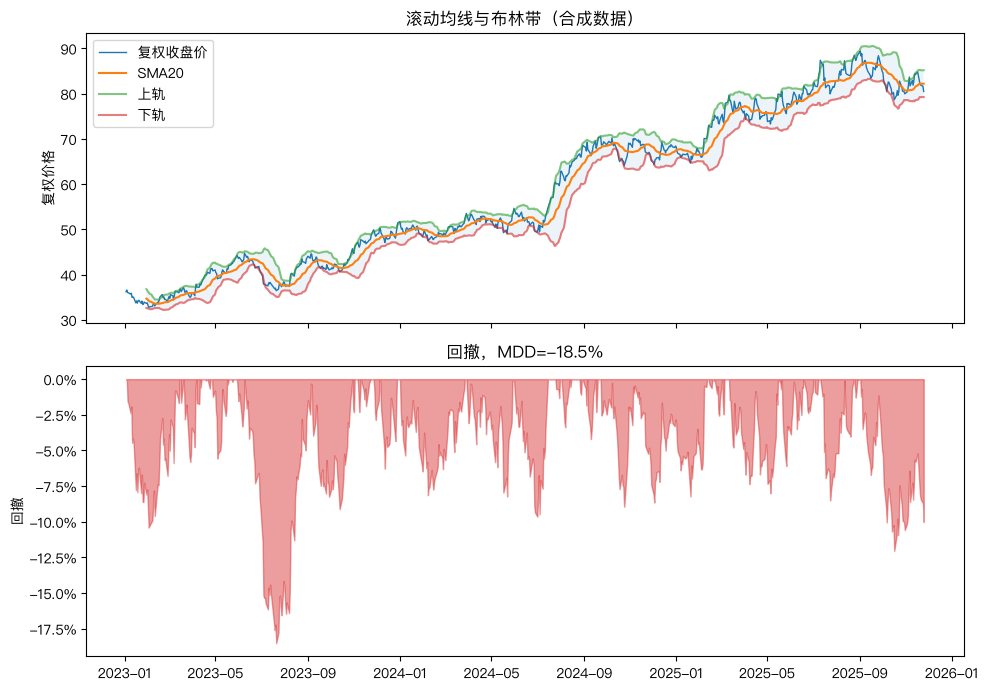

In [14]:
# 同时绘制价格指标与回撤；图中的收益和价格均来自合成数据。
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(adj_close, label="复权收盘价", linewidth=1)
axes[0].plot(ma20, label="SMA20")
axes[0].plot(upper, label="上轨", alpha=0.6)
axes[0].plot(lower, label="下轨", alpha=0.6)
axes[0].fill_between(adj_close.index, lower, upper, alpha=0.08)
axes[0].legend()
axes[0].set_title("滚动均线与布林带（合成数据）")
axes[0].set_ylabel("复权价格")
axes[1].fill_between(drawdown.index, drawdown, 0, color="tab:red", alpha=0.45)
axes[1].set_title(f"回撤，MDD={max_drawdown:.1%}")
axes[1].set_ylabel("回撤")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "36_rolling_and_drawdown.png", dpi=140)
plt.show()

## 方法边界

- `rolling(window=20)` 统计最近 20 个观测，不保证等于 20 个自然日。
- `ewm(span=20)` 是指数衰减，不是只保留 20 个观测的硬窗口；`min_periods` 只是输出门槛。
- 均线是平滑后的历史，不会自动产生预测力。
- `center=True` 会把未来值放入当前窗口，不可直接用于历史信号。
- `shift(1)` 只是一期延迟教学；真实执行需明确下单时点、可成交价格、滑点、涨跌停和停牌。
- 布林带的两倍标准差只是惯例，金融价格和收益不满足固定正态假设。
- 本课只把收益率首项设为 0 以建立净值起点；真实行情的中间缺失值不能直接填 0。
- 最大回撤依赖完整路径；它不同于波动率，也不能由期末收益单独推断。

## 可复用结论与练习

可复用计算顺序是：

```text
复权价格 → 简单收益率 → 滚动/指数指标
         → 从 1.0 起步的净值 → 历史峰值 → 回撤
         → 信号生成时间 → 延迟后的持仓 → 对应收益期间
```

练习：

1. 把小序列的 `window=3` 改为 `window=2`，先手算再核对输出。
2. 比较 `ewm(span=3, adjust=False)` 与 `adjust=True`，说明前几项为何不同。
3. 使用下一交易日的 `open` 构造更明确的执行收益，比较它与一期 close-to-close 教学结果。
4. 找出最大回撤的峰值日期、谷底日期和修复日期；若样本末尾尚未修复，应明确标记。